In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
import requests

url = "https://books.toscrape.com/"

response = requests.get(url)

print(response.status_code)

200


In [4]:
html = response.text


In [5]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(html, "html.parser")

In [8]:
import requests
from bs4 import BeautifulSoup

data = []

rating_mapping = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

for page in range(1, 51):

    url = f"https://books.toscrape.com/catalogue/page-{page}.html"

    response = requests.get(url)
    soup = BeautifulSoup(response.text, "html.parser")

    books = soup.select("article.product_pod")

    for book in books:

        name = book.h3.a["title"]

        # Clean price by removing 'Â' and '£'
        price_text = book.select_one(".price_color").text.strip()
        price = float(price_text.replace("Â", "").replace("£", ""))

        rating_text = book.select_one("p.star-rating")["class"][1]
        rating = rating_mapping[rating_text]

        # Get individual book URL
        book_url = "https://books.toscrape.com/catalogue/" + book.h3.a["href"]

        # Visit individual book page
        book_response = requests.get(book_url)
        book_soup = BeautifulSoup(book_response.text, "html.parser")

        # Extract category
        category = book_soup.select("ul.breadcrumb li a")[2].text.strip()

        data.append({
            "name": name,
            "price": price,
            "rating": rating,
            "category": category
        })


1000
[{'name': 'A Light in the Attic', 'price': 51.77, 'rating': 3, 'category': 'Poetry'}, {'name': 'Tipping the Velvet', 'price': 53.74, 'rating': 1, 'category': 'Historical Fiction'}, {'name': 'Soumission', 'price': 50.1, 'rating': 1, 'category': 'Fiction'}, {'name': 'Sharp Objects', 'price': 47.82, 'rating': 4, 'category': 'Mystery'}, {'name': 'Sapiens: A Brief History of Humankind', 'price': 54.23, 'rating': 5, 'category': 'History'}]


In [15]:
df = pd.DataFrame(data)
print(df.head(5))


                                    name  price  rating            category
0                   A Light in the Attic  51.77       3              Poetry
1                     Tipping the Velvet  53.74       1  Historical Fiction
2                             Soumission  50.10       1             Fiction
3                          Sharp Objects  47.82       4             Mystery
4  Sapiens: A Brief History of Humankind  54.23       5             History


In [17]:
df.to_csv("books_data.csv", index=False)

In [21]:
df = pd.read_csv("books_data.csv")
print(df.columns)


Index(['name', 'price', 'rating', 'category'], dtype='object')


In [22]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      1000 non-null   object 
 1   price     1000 non-null   float64
 2   rating    1000 non-null   int64  
 3   category  1000 non-null   object 
dtypes: float64(1), int64(1), object(2)
memory usage: 31.4+ KB
None


In [28]:
print(df.isnull().sum())
print(df.duplicated().sum())

name        0
price       0
rating      0
category    0
dtype: int64
0


In [33]:
print(df['rating'].unique())
print(df['category'].unique())
print(df['category'].value_counts())

[3 1 4 5 2]
['Poetry' 'Historical Fiction' 'Fiction' 'Mystery' 'History' 'Young Adult'
 'Business' 'Default' 'Sequential Art' 'Music' 'Science Fiction'
 'Politics' 'Travel' 'Thriller' 'Food and Drink' 'Romance' 'Childrens'
 'Nonfiction' 'Art' 'Spirituality' 'Philosophy' 'New Adult' 'Contemporary'
 'Fantasy' 'Add a comment' 'Science' 'Health' 'Horror' 'Self Help'
 'Religion' 'Christian' 'Crime' 'Autobiography' 'Christian Fiction'
 'Biography' 'Womens Fiction' 'Erotica' 'Cultural' 'Psychology' 'Humor'
 'Historical' 'Novels' 'Short Stories' 'Suspense' 'Classics' 'Academic'
 'Sports and Games' 'Adult Fiction' 'Parenting' 'Paranormal']
category
Default               152
Nonfiction            110
Sequential Art         75
Add a comment          67
Fiction                65
Young Adult            54
Fantasy                48
Romance                35
Mystery                32
Food and Drink         30
Childrens              29
Historical Fiction     26
Poetry                 19
Classics      

In [42]:
df['category'] = df['category'].str.strip().str.lower()

In [43]:
df.head()

,name,price,rating,category
0,A Light in the Attic,51.77,3,poetry
1,Tipping the Velvet,53.74,1,historical fiction
2,Soumission,50.10,1,fiction
3,Sharp Objects,47.82,4,mystery
4,Sapiens: A Brief History of Humankind,54.23,5,history


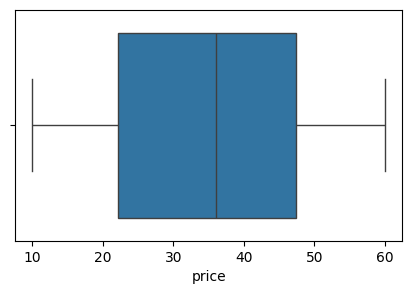

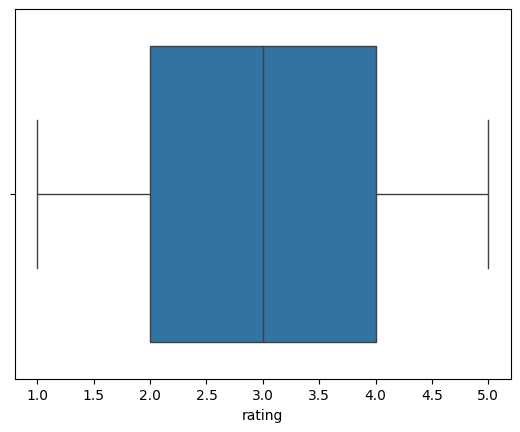

In [49]:
plt.figure(figsize=(5,3))
sns.boxplot(x=df['price'])
plt.show()
sns.boxplot(x=df['rating'])
plt.show()

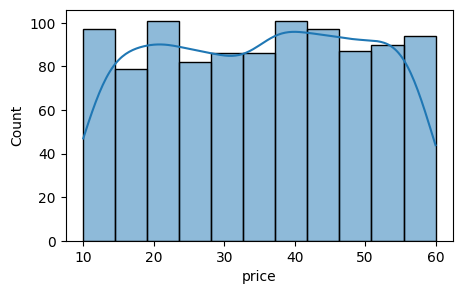

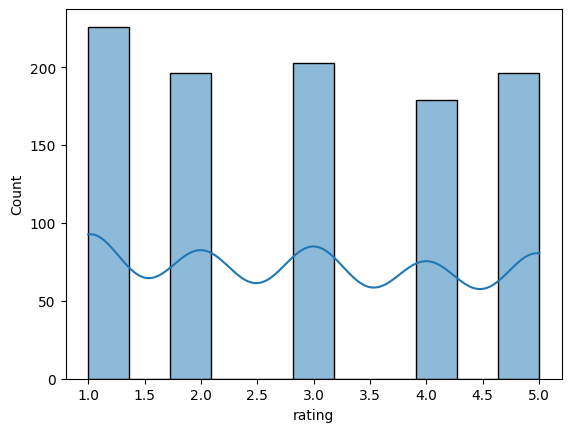

In [52]:
plt.figure(figsize=(5,3))
sns.histplot(x=df['price'],kde=True)
plt.show()
sns.histplot(x=df['rating'],kde=True)
plt.show()

In [53]:
df.describe()

,price,rating
count,1000.00000,1000.000000
mean,35.07035,2.923000
std,14.44669,1.434967
min,10.00000,1.000000
25%,22.10750,2.000000
50%,35.98000,3.000000
75%,47.45750,4.000000
max,59.99000,5.000000


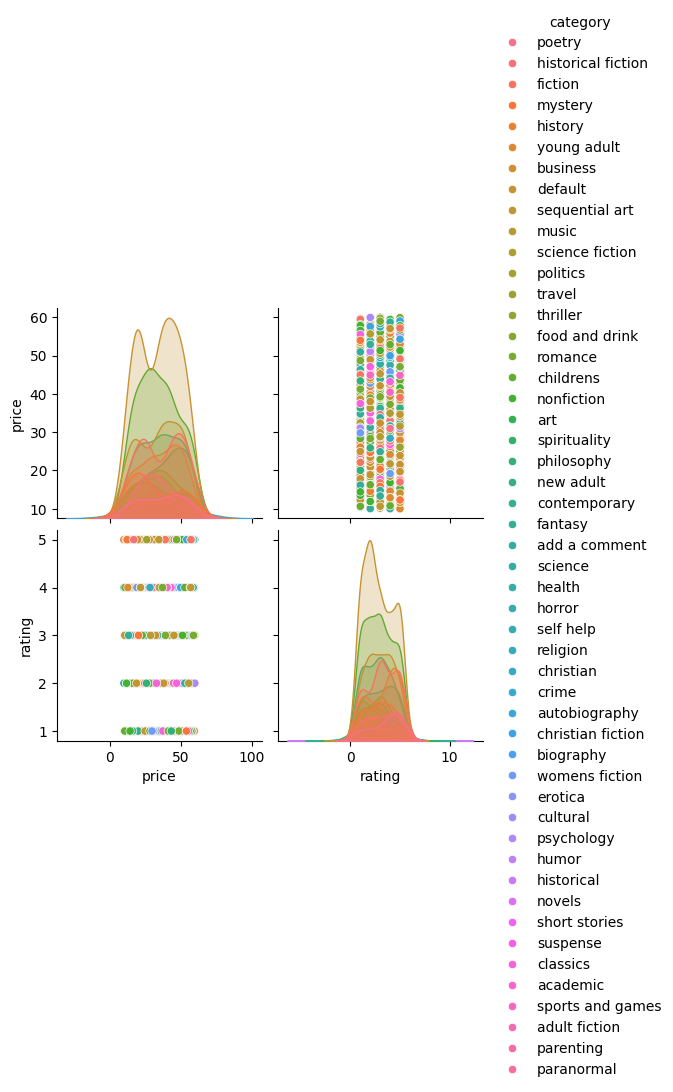

In [55]:
sns.pairplot(df,hue='category')
plt.show()

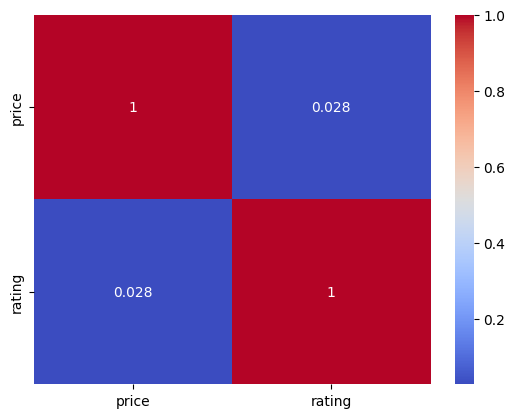

In [59]:
numCol = ['price','rating']
corr = df[numCol].corr()
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.show()

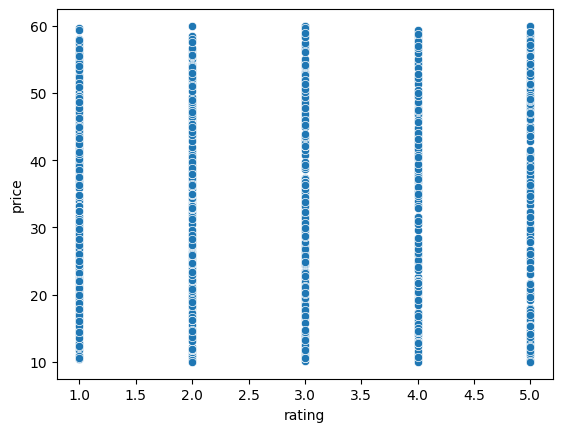

In [61]:
sns.scatterplot(y=df['price'],x=df['rating'])
plt.show()

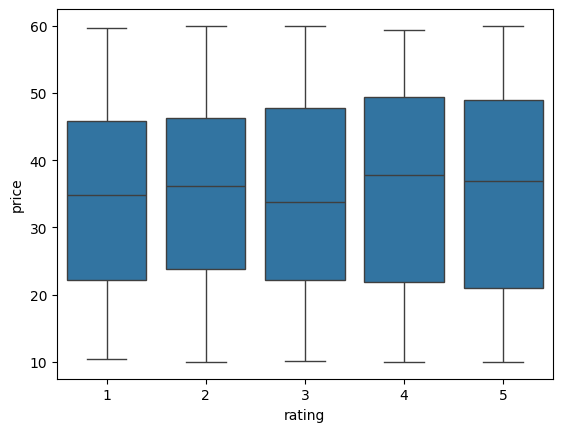

In [62]:
sns.boxplot(x=df['rating'],y=df['price'])
plt.show()

In [102]:
dfGroup = df.groupby('category').agg(
    averagePrice=('price', 'mean'),
    averageRating=('rating', 'mean'),
    numberOfBooks=('name', 'count')
)
dfGroup.reset_index(inplace=True)
mu = 0
m = 20
for i in range(len(dfGroup)):
  mu += (dfGroup['numberOfBooks'].iloc[i]*dfGroup['averagePrice'].iloc[i])
mu = mu/dfGroup['numberOfBooks'].sum()
dfGroup['adjustedPrice'] = 0
for i in range(len(dfGroup)):
  dfGroup['adjustedPrice'].iloc[i] = ((dfGroup['averagePrice'].iloc[i]*dfGroup['numberOfBooks'].iloc[i]) + (m*mu))/(dfGroup['numberOfBooks'].iloc[i]+m)
print(dfGroup.head(5))
print(mu)


        category  averagePrice  averageRating  numberOfBooks  adjustedPrice
0       academic     13.120000       2.000000              1      34.025095
1  add a comment     35.796418       2.761194             67      35.629506
2  adult fiction     15.360000       5.000000              1      34.131762
3            art     38.520000       3.625000              8      36.055964
4  autobiography     37.053333       3.000000              9      35.685759
35.070350000000005


/tmp/ipykernel_962/2320373479.py:14: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  dfGroup['adjustedPrice'].iloc[i] = ((dfGroup['averagePrice'].iloc[i]*dfGroup['numberOfBooks'].iloc[i]) + (m*mu))/(dfGroup['numberOfBooks'].iloc[i]+m)
/tmp/ipy

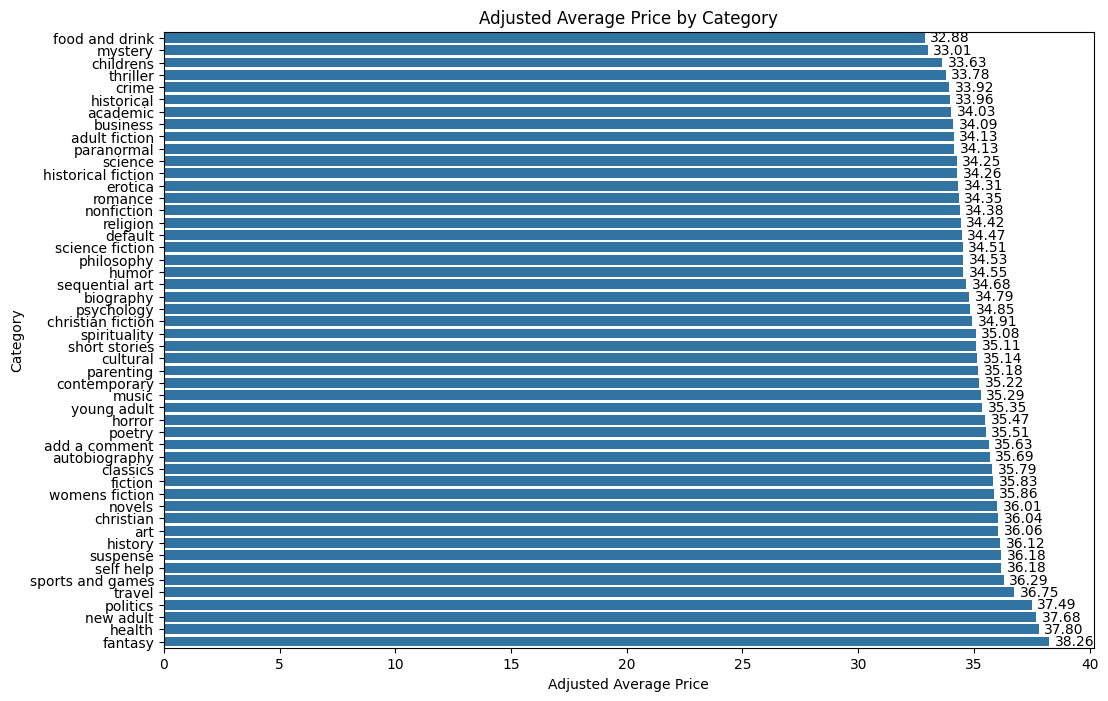

In [120]:
plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=dfGroup.sort_values('adjustedPrice'),
    x='adjustedPrice',
    y='category'
)
ax.bar_label(ax.containers[0], fmt='%.2f', padding=4)
plt.title('Adjusted Average Price by Category')
plt.xlabel('Adjusted Average Price')
plt.ylabel('Category')
plt.show()

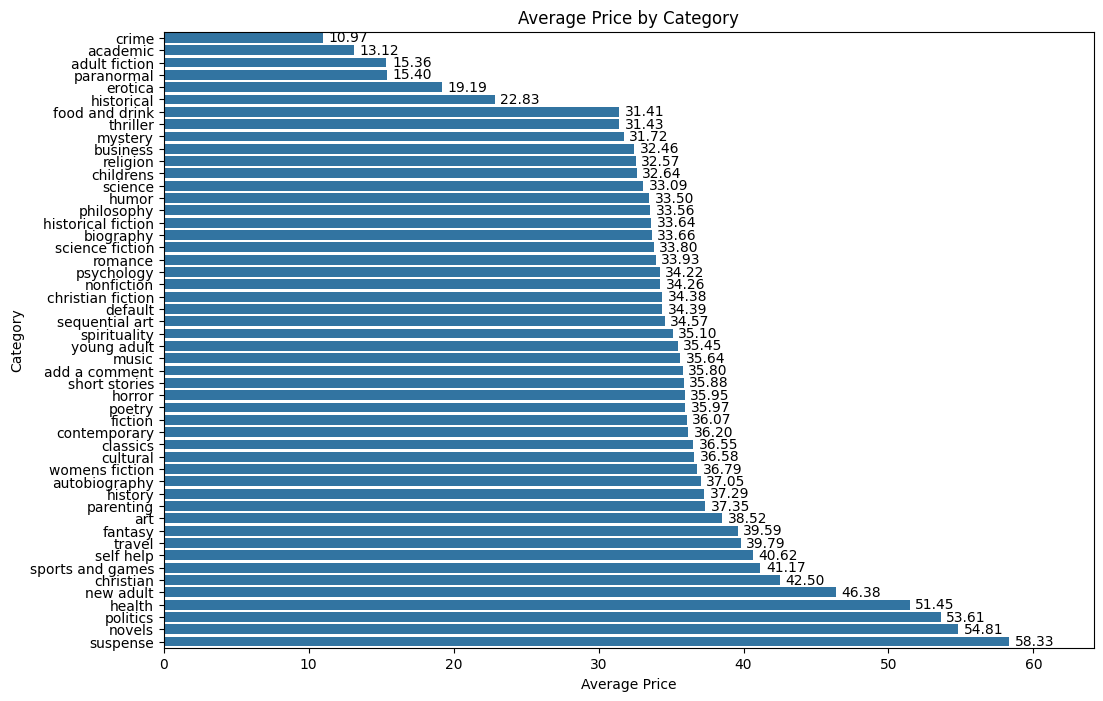

In [119]:
plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=dfGroup.sort_values('averagePrice'),
    x='averagePrice',
    y='category'
)
ax.bar_label(ax.containers[0], fmt='%.2f', padding=4)
plt.xlim(0, df_sorted['averagePrice'].max() * 1.1)
plt.xlim(0, df_sorted['averagePrice'].max() * 1.1)
plt.title('Average Price by Category')
plt.xlabel('Average Price')
plt.ylabel('Category')
plt.show()

/tmp/ipykernel_962/1849581535.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


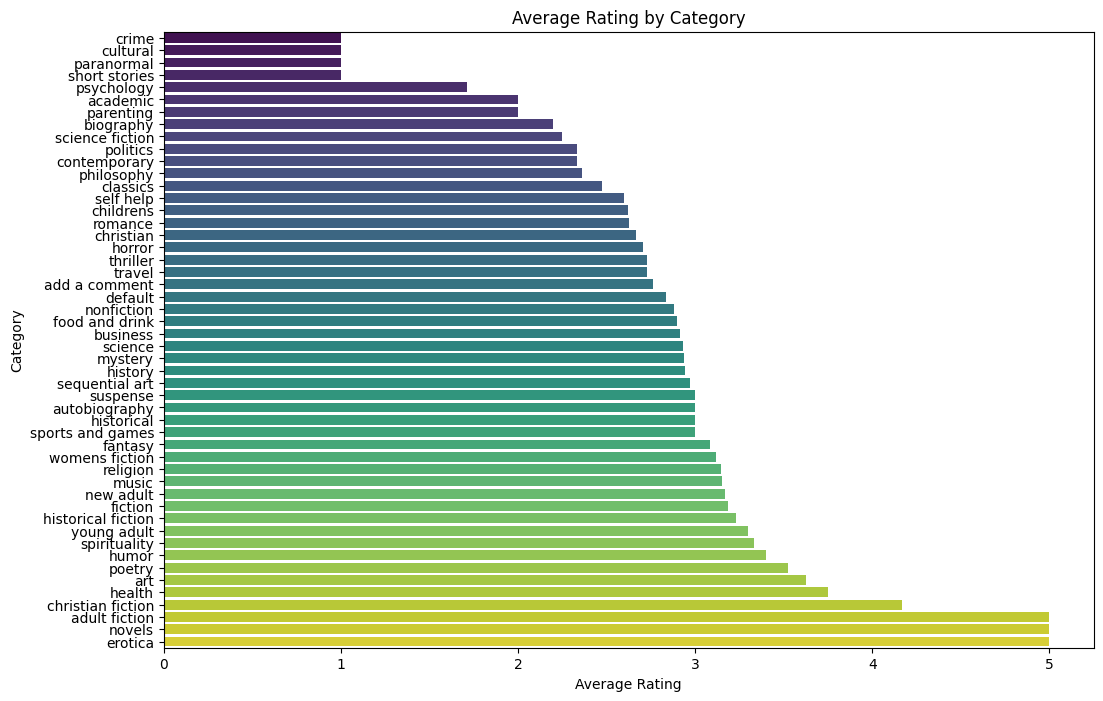

In [109]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=dfGroup.sort_values('averageRating'),
    x='averageRating',
    y='category',
    palette='viridis'
)

plt.title('Average Rating by Category')
plt.xlabel('Average Rating')
plt.ylabel('Category')
plt.show()

In [124]:
X = df[['rating', 'category']]
y = df['price']
X = pd.get_dummies(X, columns=['category'], dtype=int)

print(X.head())
print(X.shape)

   rating  category_academic  category_add a comment  category_adult fiction  \
0       3                  0                       0                       0   
1       1                  0                       0                       0   
2       1                  0                       0                       0   
3       4                  0                       0                       0   
4       5                  0                       0                       0   

   category_art  category_autobiography  category_biography  \
0             0                       0                   0   
1             0                       0                   0   
2             0                       0                   0   
3             0                       0                   0   
4             0                       0                   0   

   category_business  category_childrens  category_christian  ...  \
0                  0                   0                   0  ...   
1 

MODEL 1: RATING ONLY
--------------------
MAE: 12.657940058577998
RMSE: 14.541452750770345
R2: -0.006618384017733847

MODEL 2: RATING + CATEGORY
-------------------------
MAE: 12.901293135058438
RMSE: 14.984234395039694
R2: -0.06885398491164385

MODEL COMPARISON
               Model        MAE       RMSE        R2
0        Rating Only  12.657940  14.541453 -0.006618
1  Rating + Category  12.901293  14.984234 -0.068854


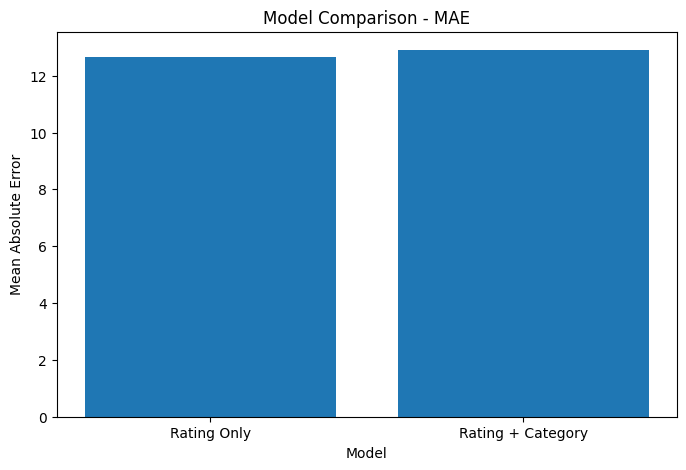

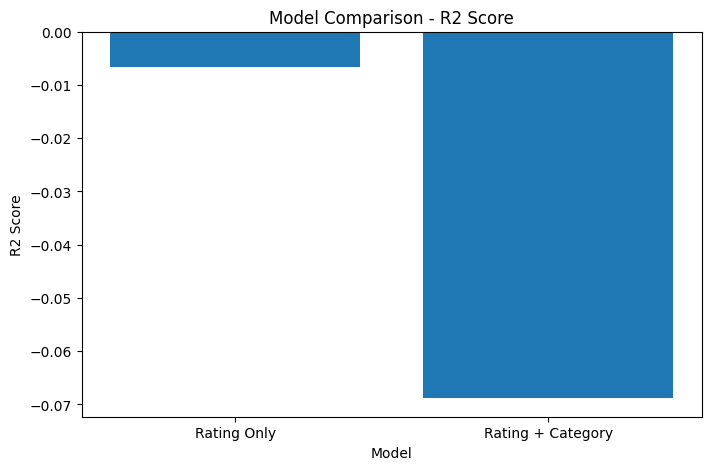

In [136]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ==========================================
# 2. PREPARE FEATURES AND TARGET
# ==========================================

y = df['price']

# Model 1: Rating only
X1 = df[['rating']]

# Model 2: Rating + Category
X2 = df[['rating', 'category']]

# Convert categorical category into numerical columns
X2 = pd.get_dummies(X2, columns=['category'], dtype=int)


# ==========================================
# 3. TRAIN-TEST SPLIT
# ==========================================

# Model 1 split
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y, test_size=0.2, random_state=42
)

# Model 2 split
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42
)


# ==========================================
# 4. CREATE AND TRAIN MODEL 1
# ==========================================

model1 = LinearRegression()

model1.fit(X1_train, y1_train)


# ==========================================
# 5. CREATE AND TRAIN MODEL 2
# ==========================================

model2 = LinearRegression()

model2.fit(X2_train, y2_train)


# ==========================================
# 6. MAKE PREDICTIONS
# ==========================================

y_pred1 = model1.predict(X1_test)

y_pred2 = model2.predict(X2_test)


# ==========================================
# 7. EVALUATE MODEL 1
# ==========================================

mae1 = mean_absolute_error(y1_test, y_pred1)

rmse1 = mean_squared_error(y1_test, y_pred1) ** 0.5

r2_1 = r2_score(y1_test, y_pred1)


# ==========================================
# 8. EVALUATE MODEL 2
# ==========================================

mae2 = mean_absolute_error(y2_test, y_pred2)

rmse2 = mean_squared_error(y2_test, y_pred2) ** 0.5

r2_2 = r2_score(y2_test, y_pred2)


# ==========================================
# 9. DISPLAY RESULTS
# ==========================================

print("MODEL 1: RATING ONLY")
print("--------------------")
print("MAE:", mae1)
print("RMSE:", rmse1)
print("R2:", r2_1)

print("\nMODEL 2: RATING + CATEGORY")
print("-------------------------")
print("MAE:", mae2)
print("RMSE:", rmse2)
print("R2:", r2_2)


# ==========================================
# 10. MODEL COMPARISON TABLE
# ==========================================

results = pd.DataFrame({
    'Model': ['Rating Only', 'Rating + Category'],
    'MAE': [mae1, mae2],
    'RMSE': [rmse1, rmse2],
    'R2': [r2_1, r2_2]
})

print("\nMODEL COMPARISON")
print(results)


# ==========================================
# 11. VISUALIZE MAE COMPARISON
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(results['Model'], results['MAE'])

plt.title("Model Comparison - MAE")
plt.ylabel("Mean Absolute Error")
plt.xlabel("Model")

plt.show()


# ==========================================
# 12. VISUALIZE R2 COMPARISON
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(results['Model'], results['R2'])

plt.title("Model Comparison - R2 Score")
plt.ylabel("R2 Score")
plt.xlabel("Model")

plt.show()

In [137]:
import numpy as np

# Model 1 accuracy-like score
accuracy1 = 100 - np.mean(np.abs((y1_test - y_pred1) / y1_test)) * 100

# Model 2 accuracy-like score
accuracy2 = 100 - np.mean(np.abs((y2_test - y_pred2) / y2_test)) * 100

print("Model 1 Prediction Accuracy:", accuracy1, "%")
print("Model 2 Prediction Accuracy:", accuracy2, "%")

Model 1 Prediction Accuracy: 46.19834645288995 %
Model 2 Prediction Accuracy: 44.7465965849147 %


RANDOM FOREST MODEL
-------------------
MAE: 14.122756131378592
RMSE: 16.753588268087157
R2: -0.3361799201983109
Custom Prediction Accuracy: 39.602444994336636 %

FEATURE IMPORTANCE
                        Feature  Importance
0                        rating    0.347303
27             category_mystery    0.034826
5        category_autobiography    0.033444
23             category_history    0.029554
17             category_fantasy    0.024935
39             category_science    0.023347
19      category_food and drink    0.022757
18             category_fiction    0.022723
47            category_thriller    0.021573
8            category_childrens    0.020047
36          category_psychology    0.019588
35            category_politics    0.018949
2        category_add a comment    0.018479
34              category_poetry    0.018420
24              category_horror    0.017088
42      category_sequential art    0.016967
29          category_nonfiction    0.015194
38             category_ro

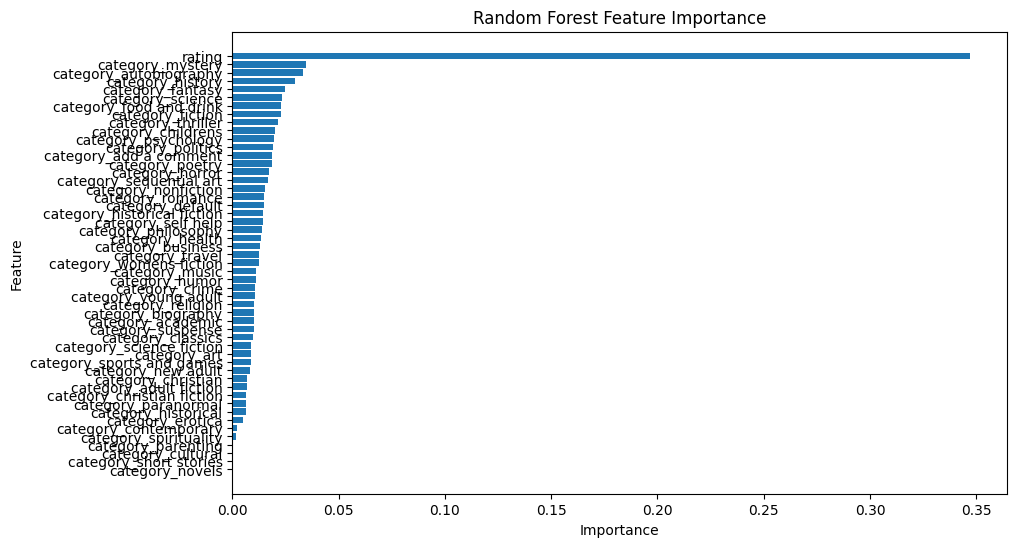

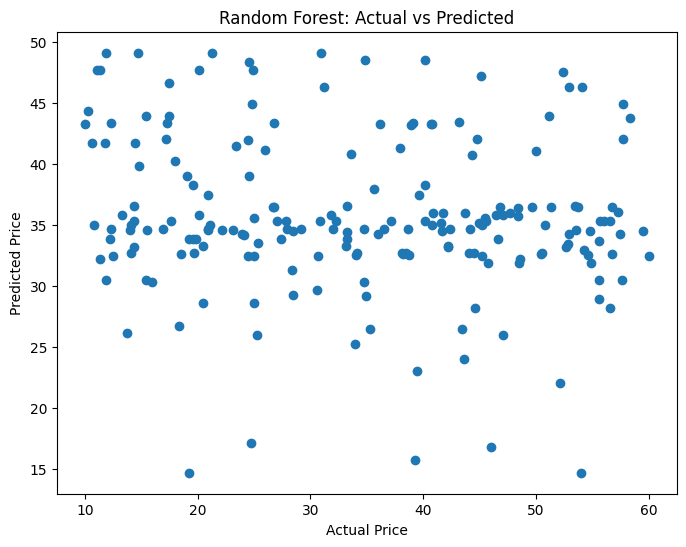

In [140]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ==========================================
# 2. PREPARE FEATURES AND TARGET
# ==========================================

X = df[['rating', 'category']]
y = df['price']


# ==========================================
# 3. ENCODE CATEGORY
# ==========================================

X = pd.get_dummies(X, columns=['category'], dtype=int)


# ==========================================
# 4. TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# ==========================================
# 5. CREATE RANDOM FOREST MODEL
# ==========================================

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)


# ==========================================
# 6. TRAIN THE MODEL
# ==========================================

rf_model.fit(X_train, y_train)


# ==========================================
# 7. MAKE PREDICTIONS
# ==========================================

y_pred_rf = rf_model.predict(X_test)


# ==========================================
# 8. EVALUATE MODEL
# ==========================================

mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = mean_squared_error(y_test, y_pred_rf) ** 0.5

r2_rf = r2_score(y_test, y_pred_rf)


print("RANDOM FOREST MODEL")
print("-------------------")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2:", r2_rf)


# ==========================================
# 9. CUSTOM ACCURACY-LIKE SCORE (OPTIONAL)
# ==========================================

accuracy_rf = 100 - np.mean(
    np.abs((y_test - y_pred_rf) / y_test)
) * 100

print("Custom Prediction Accuracy:", accuracy_rf, "%")


# ==========================================
# 10. FEATURE IMPORTANCE
# ==========================================

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance', ascending=False
)

print("\nFEATURE IMPORTANCE")
print(importance)


# ==========================================
# 11. VISUALIZE FEATURE IMPORTANCE
# ==========================================

plt.figure(figsize=(10, 6))

plt.barh(
    importance['Feature'],
    importance['Importance']
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.gca().invert_yaxis()

plt.show()


# ==========================================
# 12. ACTUAL VS PREDICTED
# ==========================================

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_rf)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Random Forest: Actual vs Predicted")

plt.show()

In [141]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    'Model': ['Linear Regression (Rating)',
              'Linear Regression (Rating + Category)',
              'Random Forest (Rating + Category)'],

    'MAE': [mae1, mae2, mae_rf],
    'RMSE': [rmse1, rmse2, rmse_rf],
    'R2': [r2_1, r2_2, r2_rf]
})

print(results)

                                   Model        MAE       RMSE        R2
0             Linear Regression (Rating)  12.657940  14.541453 -0.006618
1  Linear Regression (Rating + Category)  12.901293  14.984234 -0.068854
2      Random Forest (Rating + Category)  14.122756  16.753588 -0.336180


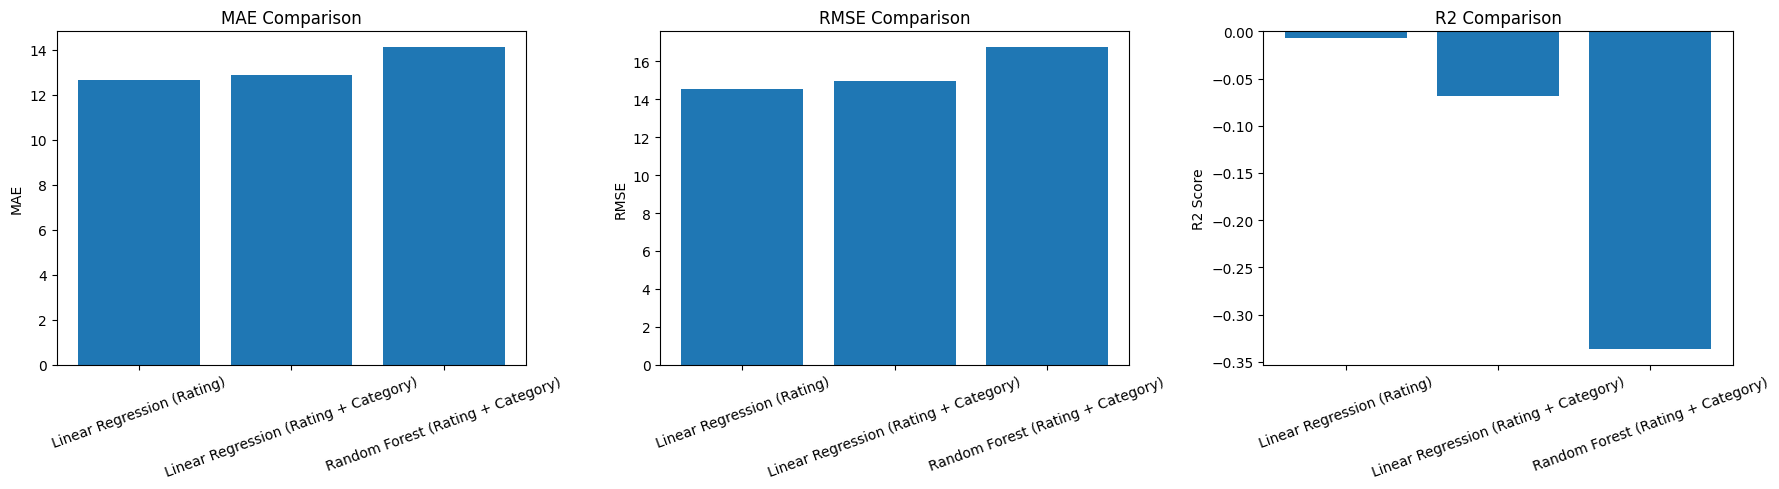

In [146]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# MAE
axes[0].bar(results['Model'], results['MAE'])
axes[0].set_title('MAE Comparison')
axes[0].set_ylabel('MAE')

# RMSE
axes[1].bar(results['Model'], results['RMSE'])
axes[1].set_title('RMSE Comparison')
axes[1].set_ylabel('RMSE')

# R2
axes[2].bar(results['Model'], results['R2'])
axes[2].set_title('R2 Comparison')
axes[2].set_ylabel('R2 Score')

for ax in axes:
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()